
--- Dataset Overview ---
  manufacturer    model   type drive_type fuel_type  color  battery_kwh  \
0          BYD  Model S  Coupe        FWD  Electric   Blue        84.93   
1        Lucid      EV6  Sedan        AWD  Electric   Blue        65.14   
2   Volkswagen      EV6    SUV        FWD    Hybrid  White        22.75   
3          BMW    Ioniq  Sedan        AWD    Hybrid  Black        71.72   
4   Volkswagen  Model 3  Truck        AWD    Hybrid  Green        62.99   

   range_km  charging_time_hr  fast_charging  ...       city seats price_usd  \
0    464.06              0.85           True  ...   Shanghai     7   32213.0   
1    345.36              2.03           True  ...      Tokyo     7   31125.0   
2    104.25              0.22           True  ...       Oslo     5   15674.0   
3    341.74              0.48          False  ...  Vancouver     2   24044.0   
4    338.16              0.79           True  ...   Shenzhen     4   29567.0   

   efficiency_score  acceleration_0_100_km

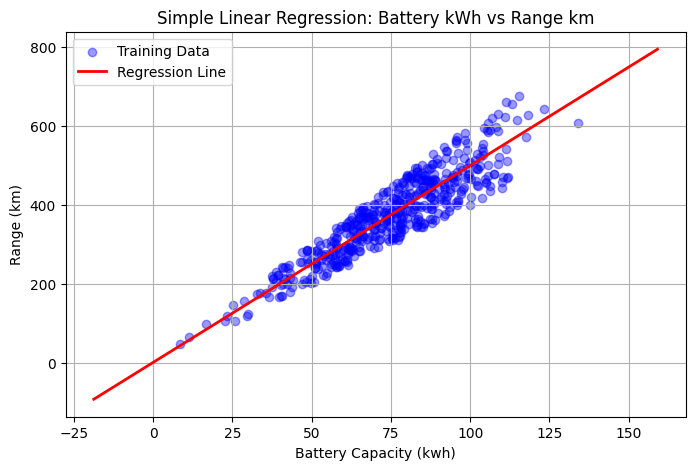


Calculated Coefficients (b0, b1, b2):
b0 (Intercept)   : 0.4382
b1 (battery_kwh) : 5.0016
b2 (price_usd)   : -0.0000

[Multiple Linear Regression Evaluation]
Mean Absolute Error (MAE) : 37.4671
Root Mean Squared Error   : 44.8210

                      Model   Independent Variables       MAE      RMSE
  Simple Linear Regression             battery_kwh 37.467794 44.821184
Multiple Linear Regression battery_kwh + price_usd 37.467146 44.821004

--- Sample Imputed Values Comparison ---
 battery_kwh  price_usd  Actual_range_km  Simple_Reg_Imputed  Multiple_Reg_Imputed
       79.37    36801.0           463.82          396.904148            396.824450
       91.70    42283.0           453.40          458.514530            458.406177
      102.79    43204.0           471.87          513.928895            513.858979
       78.00    28254.0           351.04          390.058550            390.109149
      112.44    48332.0           560.31          562.147888            562.042134


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset directly from the local path
file_path = '/content/EV_dataset.csv'
df = pd.read_csv(file_path)

print("\n--- Dataset Overview ---")
print(df.head())
print("\nDataset Shape:", df.shape)

np.random.seed(42)
df_missing = df.copy()

missing_mask = np.random.rand(len(df_missing)) < 0.10
actual_missing_values = df_missing.loc[missing_mask, 'range_km'].copy()
df_missing.loc[missing_mask, 'range_km'] = np.nan

print(f"\nTotal missing values introduced in 'range_km': {missing_mask.sum()}")

train_df = df_missing[df_missing['range_km'].notnull()].copy()
test_df = df_missing[df_missing['range_km'].isnull()].copy()

x_train = train_df['battery_kwh'].values
y_train = train_df['range_km'].values

x_bar = np.mean(x_train)
y_bar = np.mean(y_train)

w1 = np.sum((x_train - x_bar) * (y_train - y_bar)) / np.sum((x_train - x_bar) ** 2)
w0 = y_bar - (w1 * x_bar)

print(f"\nCalculated Intercept (w0) : {w0:.4f}")
print(f"... Calculated Slope (w1)     : {w1:.4f}")
print(f"Regression Equation       : range_km = {w0:.4f} + {w1:.4f} * battery_kwh")

x_test = test_df['battery_kwh'].values
simple_pred = w0 + w1 * x_test

simple_mae = np.mean(np.abs(actual_missing_values - simple_pred))
simple_rmse = np.sqrt(np.mean((actual_missing_values - simple_pred) ** 2))

print(f"\n[Simple Linear Regression Evaluation]")
print(f"Mean Absolute Error (MAE) : {simple_mae:.4f}")
print(f"Root Mean Squared Error   : {simple_rmse:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(x_train[:500], y_train[:500], alpha=0.4, label='Training Data', color='blue')
x_range = np.linspace(x_train.min(), x_train.max(), 100)
plt.plot(x_range, w0 + w1 * x_range, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Battery Capacity (kwh)')
plt.ylabel('Range (km)')
plt.title('Simple Linear Regression: Battery kWh vs Range km')
plt.legend()
plt.grid(True)
plt.show()

X_train_mat = np.column_stack([
    np.ones(len(train_df)),
    train_df['battery_kwh'].values,
    train_df['price_usd'].values
])
Y_train_mat = train_df['range_km'].values

b = np.linalg.inv(X_train_mat.T @ X_train_mat) @ X_train_mat.T @ Y_train_mat

print(f"\nCalculated Coefficients (b0, b1, b2):")
print(f"b0 (Intercept)   : {b[0]:.4f}")
print(f"b1 (battery_kwh) : {b[1]:.4f}")
print(f"b2 (price_usd)   : {b[2]:.4f}")

X_test_mat = np.column_stack([
    np.ones(len(test_df)),
    test_df['battery_kwh'].values,
    test_df['price_usd'].values
])

multiple_pred = X_test_mat @ b

multiple_mae = np.mean(np.abs(actual_missing_values - multiple_pred))
multiple_rmse = np.sqrt(np.mean((actual_missing_values - multiple_pred) ** 2))

print(f"\n[Multiple Linear Regression Evaluation]")
print(f"Mean Absolute Error (MAE) : {multiple_mae:.4f}")
print(f"Root Mean Squared Error   : {multiple_rmse:.4f}")

comparison_df = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'Independent Variables': ['battery_kwh', 'battery_kwh + price_usd'],
    'MAE': [simple_mae, multiple_mae],
    'RMSE': [simple_rmse, multiple_rmse]
})

print("\n", comparison_df.to_string(index=False))

imputed_sample = test_df[['battery_kwh', 'price_usd']].copy().head(5)
imputed_sample['Actual_range_km'] = actual_missing_values.head(5).values
imputed_sample['Simple_Reg_Imputed'] = simple_pred[:5]
imputed_sample['Multiple_Reg_Imputed'] = multiple_pred[:5]

print("\n--- Sample Imputed Values Comparison ---")
print(imputed_sample.to_string(index=False))